# Trải nghiệm khách hàng


| # | Câu hỏi | 
|---|---|
| 1 | Bức tranh tổng quan trải nghiệm khách hàng ra sao? | 
| 2 | Khách hàng hài lòng đến mức nào? |
| 3 | Trải nghiệm đang tốt lên hay xấu đi theo thời gian? | |
| 4 | Giao hàng liên quan thế nào đến sự hài lòng? | 
| 5 | Khu vực nào đang phục vụ kém? | 
| 6 | Ngành hàng nào gây bất mãn? | 
| 7 | Người bán nào kéo trải nghiệm xuống? | 
| 8 | Đặc điểm đơn hàng / thanh toán có liên quan đến hài lòng không? | 
| 9 | Trải nghiệm đơn đầu tiên có liên quan đến việc khách quay lại? | 
| 10 | Yếu tố nào gắn với review tiêu cực nhiều nhất? | 
| 11 | Tóm lại, insight quan trọng nhất là gì? |

### Quy ước
- **Tập đơn:** mọi đơn được đặt (kể cả đơn hủy), khác `executive_overview` vốn chỉ tính đơn hợp lệ. Vì vậy điểm review TB ở đây (4,09) hơi thấp hơn bên đó (4,12).
- **Kỳ phân tích** của biểu đồ theo tháng: cửa sổ xu hướng chung của mọi notebook, suy ra từ dữ liệu trong `common.connect()` (hiện là 01/2017 → 08/2018).
- **Đối tượng phân tích:** Đơn hàng
- *Điểm của 1 đơn hàng* = `AVG(review_score)`; *nhóm sao của đơn* = điểm làm tròn.
- *Đơn không hài lòng* = có **ít nhất một** review 1–2★
- *Đơn hài lòng* = **mọi** review đều 4–5★
- **Quay lại mua** = khách có đơn thứ hai trong vòng **90 ngày** sau đơn đầu tiên.

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from common import *   # kết nối, kỳ phân tích, bảng màu, hàm trục

con, P = connect(["fact_payments", "dim_seller", "dim_product", "dim_category"])

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


In [2]:
apply_theme()
SCORE_COLORS = {1: C_BAD, 2: C_ORANGE, 3: C_YELLOW, 4: "#84CC16", 5: C_GOOD}

# Bộ chỉ số trải nghiệm dùng chung trong mọi GROUP BY: số đơn, điểm TB, % đơn không hài lòng
CX_METRICS = "count(*) AS orders, avg(review_score) AS avg_score, avg(is_negative) AS negative_rate"

### Tạo bảng phân tích đơn hàng (`order_cx`)
Lấy `order_base` (1 dòng / đơn, **mọi trạng thái**, tạo sẵn trong `connect()`): điểm review, cờ hài lòng, thời gian giao, trễ hạn, giá trị đơn,
số sản phẩm, phí ship, bang của khách; ghép thêm hình thức thanh toán chính từ `order_payment` (`create_order_payment()` của `common/tables.py`).

Tạo 3 bảng phụ dùng cho quá trình phân tích:

- Bảng `delivered`: Chứa các đơn đã giao thành công, có đủ số ngày giao thực tế và ngày giao dự kiến.

- Bảng `reviewed`: Chứa các đơn hàng có review.

- Bảng `reviewed_delivered`: Chứa các đơn vừa đã giao đầy đủ thông tin vừa có review.

In [3]:
create_order_payment()
con.execute('''
CREATE OR REPLACE TABLE order_cx AS
SELECT o.*,
       pay.payment_value, pay.installments, pay.payment_type,
       CAST(round(o.review_score) AS INTEGER) AS score_int,
       CASE WHEN o.is_negative = 1 THEN 'Không hài lòng (1–2★)'
            WHEN o.is_positive = 1 THEN 'Hài lòng (4–5★)'
            WHEN o.review_score IS NOT NULL THEN 'Trung lập (3★)' END AS satisfaction,
       o.freight_value / nullif(o.product_value, 0) AS freight_ratio
FROM order_base o
LEFT JOIN order_payment pay ON pay.order_key = o.order_key
''')

# Đơn đã giao, đủ ngày giao thực tế & dự kiến → dùng cho mọi chỉ số giao hàng
con.execute("CREATE OR REPLACE TABLE delivered AS SELECT * FROM order_cx WHERE is_late IS NOT NULL AND delivery_days IS NOT NULL")
con.execute("CREATE OR REPLACE TABLE reviewed AS SELECT * FROM order_cx WHERE review_score IS NOT NULL")
con.execute("CREATE OR REPLACE TABLE reviewed_delivered AS SELECT * FROM delivered WHERE review_score IS NOT NULL")
print(q("SELECT (SELECT count(*) FROM order_cx) AS orders, (SELECT count(*) FROM delivered) AS delivered_orders")
      .to_string(index=False))

 orders  delivered_orders
  98059             95097


## 1. KPI tổng quan trải nghiệm khách hàng
*Câu hỏi: "Trải nghiệm khách hàng của hệ thống đang ở mức nào?"*

In [4]:
kpi = {
    **q('''SELECT count(*) AS total_orders, avg(is_delivered) AS delivered_rate, avg(is_canceled) AS cancel_rate,
                  avg(review_score) AS avg_review_score, avg(is_positive) AS positive_rate, avg(is_negative) AS negative_rate
           FROM order_cx''').iloc[0].to_dict(),
    **q(f'''SELECT avg(delivery_days) AS avg_delivery_days, {median_sql("delivery_days")} AS median_delivery_days,
                  avg(estimated_delivery_days) AS avg_estimated_days, avg(1 - is_late) AS on_time_rate
           FROM delivered''').iloc[0].to_dict(),
    **q('''SELECT count(*) FILTER (WHERE review_score IS NOT NULL) AS reviewed_orders,
                  avg(CAST(review_score IS NOT NULL AS INTEGER)) AS review_rate
           FROM order_cx''').iloc[0].to_dict(),
}
labels = {
    "total_orders": ("Tổng số đơn", "{:,.0f}"),
    "reviewed_orders": ("Số đơn có đánh giá", "{:,.0f}"),
    "review_rate": ("% đơn có đánh giá / tổng đơn", "{:.1%}"),
    "avg_review_score": ("Điểm review TB (1–5)", "{:.2f}"),
    "positive_rate": ("% đơn hài lòng (4–5★)", "{:.1%}"),
    "negative_rate": ("% đơn không hài lòng (1–2★)", "{:.1%}"),
    "on_time_rate": ("% giao đúng hạn", "{:.1%}"),
    "avg_delivery_days": ("Thời gian giao TB (ngày)", "{:.1f}"),
    "median_delivery_days": ("Thời gian giao trung vị (ngày)", "{:.0f}"),
    "avg_estimated_days": ("Thời gian hứa giao TB (ngày)", "{:.1f}"),
    "delivered_rate": ("% đơn giao thành công", "{:.1%}"),
    "cancel_rate": ("% đơn bị hủy", "{:.2%}"),
}
print(pd.DataFrame([(lbl, fmt.format(kpi[key])) for key, (lbl, fmt) in labels.items()], columns=["KPI", "Giá trị"])
      .to_string(index=False))

                           KPI Giá trị
                   Tổng số đơn  98,059
            Số đơn có đánh giá  96,725
  % đơn có đánh giá / tổng đơn   98.6%
          Điểm review TB (1–5)    4.09
         % đơn hài lòng (4–5★)   77.0%
   % đơn không hài lòng (1–2★)   14.7%
               % giao đúng hạn   93.2%
      Thời gian giao TB (ngày)    12.2
Thời gian giao trung vị (ngày)      10
  Thời gian hứa giao TB (ngày)    23.4
         % đơn giao thành công   97.0%
                  % đơn bị hủy   0.64%


> **🔎 Kết quả chính**
> - 99.441 đơn; điểm review TB **4,09**; **77,1%** đơn hài lòng và **14,6%** đơn không hài lòng.
> - Vận hành giao hàng tốt trên giấy tờ: **93,2%** đơn giao đúng hạn, giao TB 12,5 ngày (trung vị 10) trong khi hứa giao TB 24,4 ngày.

## 2. Mức độ hài lòng
*Câu hỏi: "Khách hàng chấm điểm ra sao? Tỷ lệ khách bất mãn lớn đến đâu?"*

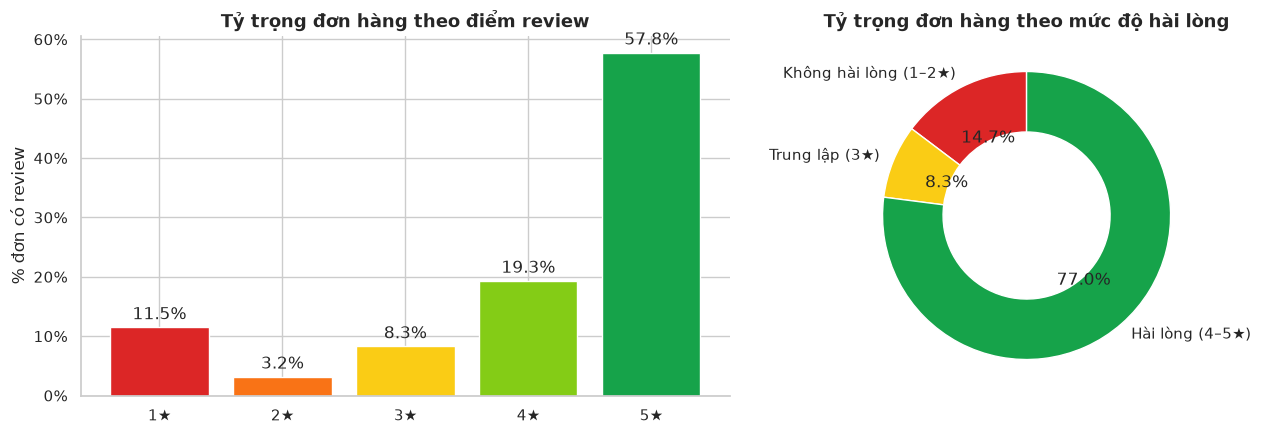

In [5]:
score_dist = q("SELECT score_int, count(*) AS n FROM reviewed GROUP BY 1 ORDER BY 1")
score_dist["share"] = score_dist.n / score_dist.n.sum()
sat = q("SELECT satisfaction, count(*) AS n FROM reviewed GROUP BY 1").set_index("satisfaction")["n"]
sat = sat.reindex(["Không hài lòng (1–2★)", "Trung lập (3★)", "Hài lòng (4–5★)"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
bars = ax1.bar(score_dist.score_int.astype(str) + "★", score_dist.share,
               color=[SCORE_COLORS[s] for s in score_dist.score_int])
ax1.bar_label(bars, labels=[f"{v:.1%}" for v in score_dist.share], padding=3)
ax1.set_title("Tỷ trọng đơn hàng theo điểm review"); pct_axis(ax1); ax1.set_ylabel("% đơn có review")
ax2.pie(sat, labels=sat.index, autopct="%1.1f%%", startangle=90, colors=[C_BAD, C_YELLOW, C_GOOD],
        wedgeprops=dict(width=0.42, edgecolor="white"))
ax2.set_title("Tỷ trọng đơn hàng theo mức độ hài lòng")
plt.tight_layout(); plt.show()

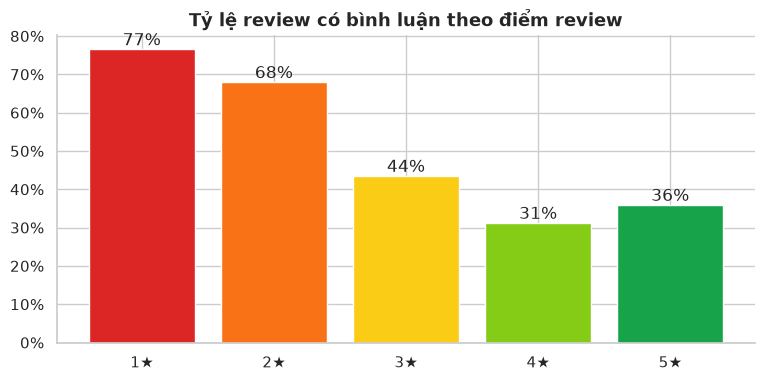

In [6]:
# Khách có để lại bình luận không? (tính trên từng review — bình luận là tín hiệu cảm xúc mạnh)
comment = q('''SELECT review_score, avg(CAST(review_comment_message IS NOT NULL AS INTEGER)) AS comment_rate
               FROM fact_reviews GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(comment.review_score.astype(str) + "★", comment.comment_rate,
              color=[SCORE_COLORS[s] for s in comment.review_score])
ax.bar_label(bars, labels=[f"{v:.0%}" for v in comment.comment_rate])
ax.set_title("Tỷ lệ review có bình luận theo điểm review"); pct_axis(ax)
plt.show()

> **🔎 Kết quả chính**
> - Phân phối: 57,8% đơn 5★, nhưng 1★ (11,4%) cao hơn hẳn 2★ (3,2%). Khách bất mãn thường chấm thẳng 1★.
> - Khách bất mãn lên tiếng nhiều hơn: **77%** review 1★ và 68% review 2★ có bình luận, so với 31–36% ở nhóm 4–5★. Bình luận là nguồn tốt để hiểu nguyên nhân bất mãn.

## 3. Xu hướng trải nghiệm theo thời gian
*Câu hỏi: "Trải nghiệm đang tốt lên hay xấu đi theo thời gian?"*

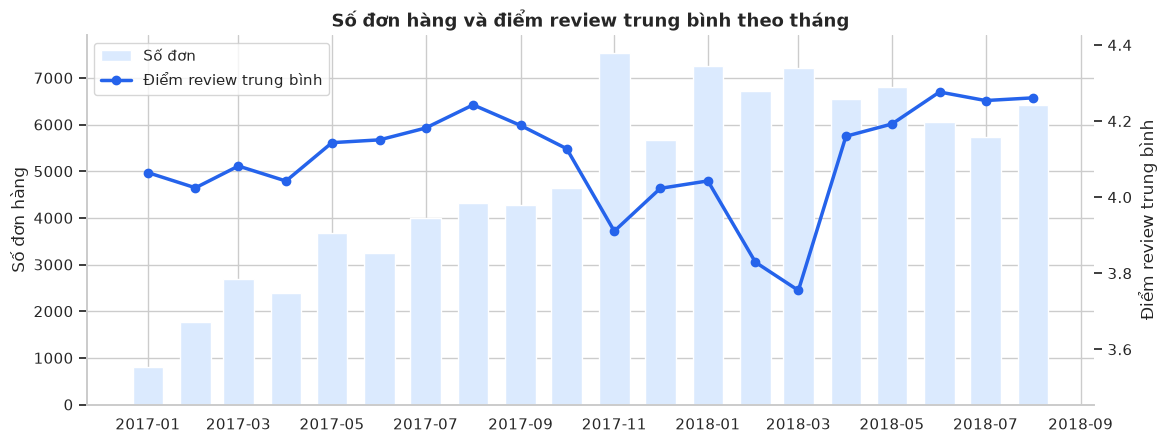

In [7]:
trend = q(f'''
    SELECT purchase_month, {CX_METRICS},
           avg(is_late) AS late_rate,
           avg(CASE WHEN is_delivered = 1 THEN delivery_days END) AS avg_delivery_days
    FROM order_cx
    WHERE {P.in_period}
    GROUP BY 1 ORDER BY 1''')

fig, ax1 = plt.subplots(figsize=(13, 4.8))
ax1.bar(trend.purchase_month, trend.orders, width=20, color="#DBEAFE", label="Số đơn")
ax1.set_ylabel("Số đơn hàng")
ax2 = ax1.twinx()
ax2.plot(trend.purchase_month, trend.avg_score, color=C_MAIN, marker="o", lw=2.5, label="Điểm review trung bình")
ax2.set_ylim(trend.avg_score.min() - 0.3, trend.avg_score.max() + 0.15); ax2.set_ylabel("Điểm review trung bình"); ax2.grid(False)
ax1.set_title("Số đơn hàng và điểm review trung bình theo tháng")
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left"); plt.show()

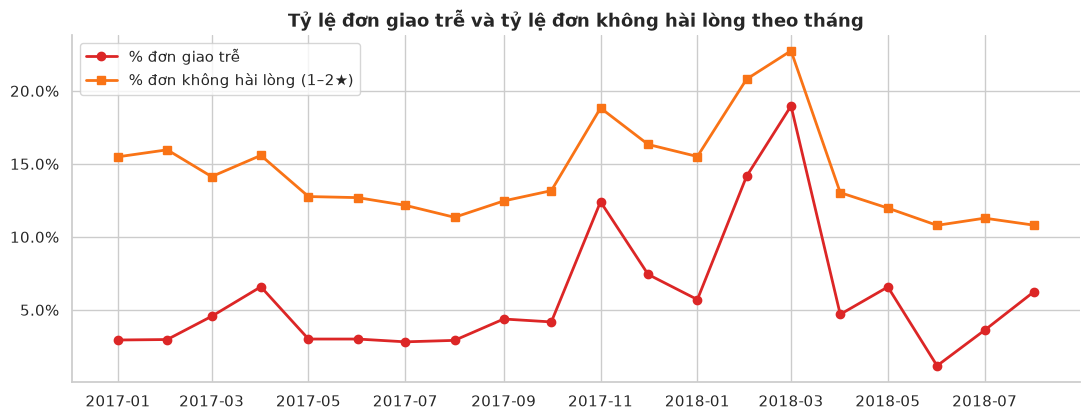

Tương quan theo tháng giữa % giao trễ và % không hài lòng: 0.861
                orders  avg_score  negative_rate  late_rate  avg_delivery_days
purchase_month                                                                
2017-01-01         799      4.065          0.155      0.029             12.084
2017-02-01        1777      4.025          0.160      0.030             12.621
2017-03-01        2681      4.082          0.141      0.046             12.398
2017-04-01        2380      4.042          0.156      0.066             14.380
2017-05-01        3685      4.143          0.128      0.030             10.768
2017-06-01        3240      4.151          0.127      0.030             11.483
2017-07-01        3994      4.182          0.122      0.028             11.153
2017-08-01        4328      4.243          0.113      0.029             10.705
2017-09-01        4272      4.188          0.125      0.044             11.401
2017-10-01        4631      4.127          0.132      0.042       

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(trend.purchase_month, trend.late_rate, color=C_BAD, marker="o", lw=2, label="% đơn giao trễ")
ax.plot(trend.purchase_month, trend.negative_rate, color=C_ORANGE, marker="s", lw=2, label="% đơn không hài lòng (1–2★)")
pct_axis(ax); ax.legend(); ax.set_title("Tỷ lệ đơn giao trễ và tỷ lệ đơn không hài lòng theo tháng")
plt.show()
print("Tương quan theo tháng giữa % giao trễ và % không hài lòng:",
      round(trend[["late_rate", "negative_rate"]].corr().iloc[0, 1], 3))
print(trend.set_index("purchase_month").round(3).to_string())

> **🔎 Kết quả chính**
> - Số đơn tăng mạnh từ 2017 sang 2018, nhưng điểm TB **giảm rõ ở 11/2017 (3,91) và 02–03/2018 (3,83 → 3,76)**, đúng các tháng % giao trễ tăng vọt (12,4%, 14,1%, 19,0%).
> - Tương quan theo tháng giữa % giao trễ và % không hài lòng là **0,86**.
> - Từ 04/2018 thời gian giao giảm còn 7,7–11 ngày, điểm TB phục hồi lên ~4,26: chất lượng đã ổn định trở lại sau giai đoạn tăng quy mô.

## 4. Trải nghiệm giao hàng
*Câu hỏi: "Giao hàng nhanh/chậm, đúng/trễ hạn liên quan đến điểm review mạnh đến mức nào?"*

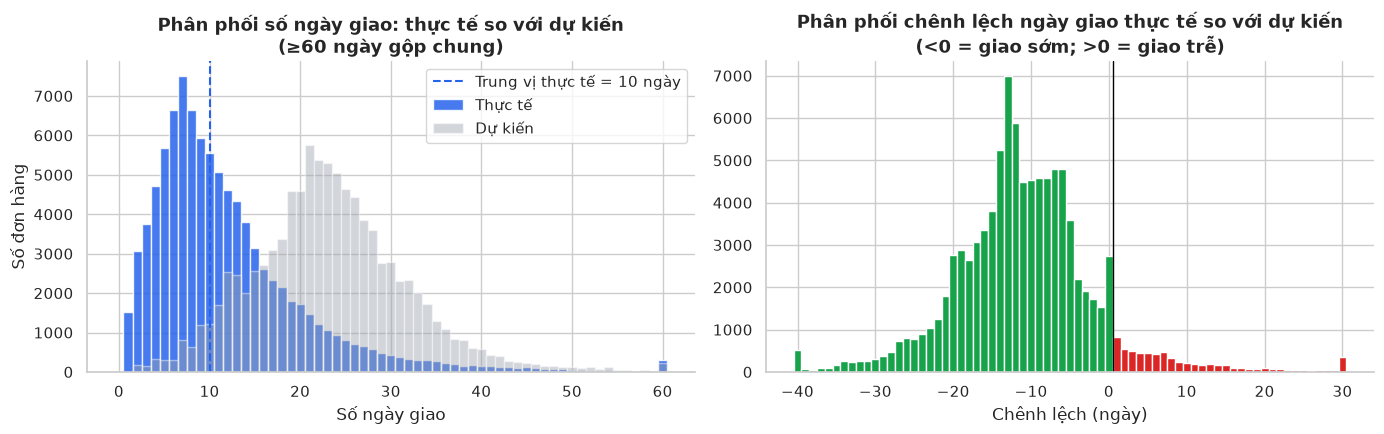

Trung vị số ngày giao sớm hơn dự kiến: 11.0


In [9]:
CLIP_DAYS = 60
h_actual = q(f"SELECT least(delivery_days, {CLIP_DAYS}) AS d, count(*) AS n FROM delivered GROUP BY 1 ORDER BY 1")
h_est = q(f"SELECT least(estimated_delivery_days, {CLIP_DAYS}) AS d, count(*) AS n FROM delivered GROUP BY 1 ORDER BY 1")
h_delay = q("SELECT greatest(least(delivery_delay_days, 30), -40) AS d, count(*) AS n FROM delivered GROUP BY 1 ORDER BY 1")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.bar(h_actual.d, h_actual.n, width=1, color=C_MAIN, alpha=0.85, label="Thực tế")
ax1.bar(h_est.d, h_est.n, width=1, color=C_GREY, alpha=0.45, label="Dự kiến")
ax1.axvline(kpi["median_delivery_days"], color=C_MAIN, ls="--",
            label=f"Trung vị thực tế = {kpi['median_delivery_days']:.0f} ngày")
ax1.legend(); ax1.set_title(f"Phân phối số ngày giao: thực tế so với dự kiến\n(≥{CLIP_DAYS} ngày gộp chung)")
ax1.set_xlabel("Số ngày giao"); ax1.set_ylabel("Số đơn hàng")
ax2.bar(h_delay.d, h_delay.n, width=1, color=np.where(h_delay.d > 0, C_BAD, C_GOOD))
ax2.axvline(0.5, color="black", lw=1)
ax2.set_title("Phân phối chênh lệch ngày giao thực tế so với dự kiến\n(<0 = giao sớm; >0 = giao trễ)"); ax2.set_xlabel("Chênh lệch (ngày)")
plt.tight_layout(); plt.show()
print("Trung vị số ngày giao sớm hơn dự kiến:", -q(f"SELECT {median_sql('delivery_delay_days')} AS m FROM delivered").m[0])

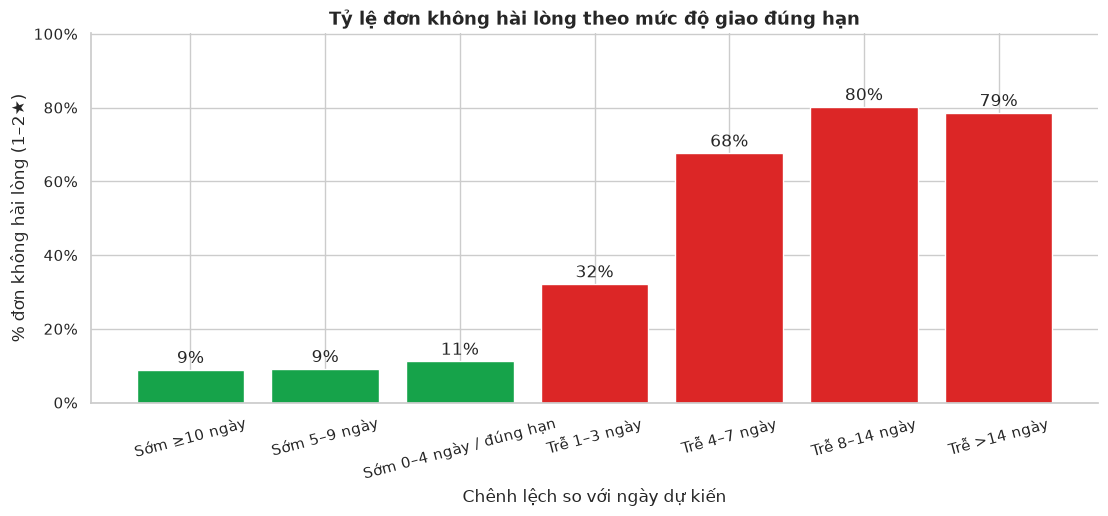

           delay_bucket  orders  avg_score  negative_rate  share_orders
           Sớm ≥10 ngày   55499      4.325          0.089         0.591
           Sớm 5–9 ngày   22140      4.279          0.092         0.236
Sớm 0–4 ngày / đúng hạn    9967      4.140          0.112         0.106
           Trễ 1–3 ngày    1829      3.293          0.321         0.019
           Trễ 4–7 ngày    1732      2.107          0.676         0.018
          Trễ 8–14 ngày    1438      1.673          0.802         0.015
           Trễ >14 ngày    1321      1.718          0.786         0.014


In [10]:
DELAY_BINS = [(-10, "Sớm ≥10 ngày"), (-5, "Sớm 5–9 ngày"), (0, "Sớm 0–4 ngày / đúng hạn"),
              (3, "Trễ 1–3 ngày"), (7, "Trễ 4–7 ngày"), (14, "Trễ 8–14 ngày")]
DELAY_ORDER = [label for _, label in DELAY_BINS] + ["Trễ >14 ngày"]
by_delay = ordered(q(f'''
    SELECT {band_sql("delivery_delay_days", DELAY_BINS, "Trễ >14 ngày", upper_inclusive=True)} AS delay_bucket, {CX_METRICS}
    FROM reviewed_delivered GROUP BY 1'''), "delay_bucket", DELAY_ORDER)
by_delay["share_orders"] = by_delay.orders / by_delay.orders.sum()

fig, ax1 = plt.subplots(figsize=(13, 4.8))
bars = ax1.bar(by_delay.delay_bucket, by_delay.negative_rate,
               color=[C_GOOD if "Sớm" in b else C_BAD for b in by_delay.delay_bucket])
ax1.bar_label(bars, labels=[f"{v:.0%}" for v in by_delay.negative_rate], padding=2)
pct_axis(ax1); ax1.set_ylabel("% đơn không hài lòng (1–2★)"); ax1.set_ylim(0, by_delay.negative_rate.max() * 1.25)
ax1.set_title("Tỷ lệ đơn không hài lòng theo mức độ giao đúng hạn"); ax1.set_xlabel("Chênh lệch so với ngày dự kiến")
plt.setp(ax1.get_xticklabels(), rotation=15); plt.show()
print(by_delay.round(3).to_string(index=False))

- **Chú thích**: Dấu `*` trên đầu mỗi cột là số sao trung bình của các đơn trong nhóm đó

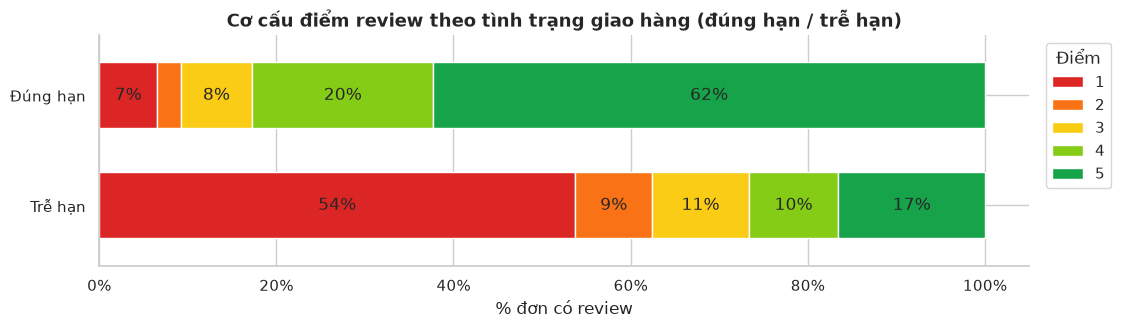

In [11]:
on_time = q('''SELECT CASE WHEN is_late = 1 THEN 'Trễ hạn' ELSE 'Đúng hạn' END AS delivery_status, score_int, count(*) AS n
               FROM reviewed_delivered GROUP BY 1, 2''')
pv = on_time.pivot(index="delivery_status", columns="score_int", values="n").fillna(0)
pv = pv.div(pv.sum(axis=1), axis=0)
ax = pv.plot(kind="barh", stacked=True, color=[SCORE_COLORS[c] for c in pv.columns], figsize=(12, 3), width=0.6)
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v:.0%}" if v > 0.04 else "" for v in c.datavalues], label_type="center")
pct_axis(ax, "x"); ax.legend(title="Điểm", bbox_to_anchor=(1.01, 1)); ax.set_ylabel("")
ax.set_title("Cơ cấu điểm review theo tình trạng giao hàng (đúng hạn / trễ hạn)"); ax.set_xlabel("% đơn có review"); plt.show()

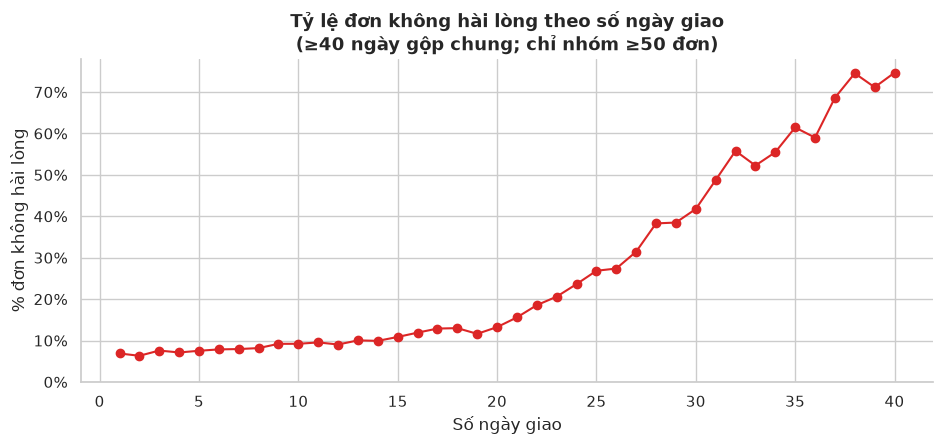

In [12]:
by_days = q(f'''SELECT least(delivery_days, 40) AS days, {CX_METRICS}
                FROM reviewed_delivered GROUP BY 1 HAVING count(*) >= 50 ORDER BY 1''')
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(by_days.days, by_days.negative_rate, marker="o", color=C_BAD)
pct_axis(ax); ax.set_ylim(0, None)
ax.set_title("Tỷ lệ đơn không hài lòng theo số ngày giao\n(≥40 ngày gộp chung; chỉ nhóm ≥50 đơn)"); ax.set_xlabel("Số ngày giao")
ax.set_ylabel("% đơn không hài lòng")
plt.show()

> **🔎 Kết quả chính**
> - Đây là phát hiện mạnh nhất: đơn giao **sớm/đúng hạn** có 9–11% không hài lòng; trễ 1–3 ngày lên **32%**; trễ 4–7 ngày **68%**; trễ ≥8 ngày **~80%**.
> - Hệ thống hứa giao rất "an toàn" (trung vị giao sớm hơn hứa 12 ngày), nhưng 6,7% đơn trễ vẫn tạo ra phần lớn trải nghiệm xấu.

## 5. Địa lý — khu vực nào đang phục vụ kém?
*Câu hỏi: "Bang nào khách phải chờ lâu nhất, trễ nhiều nhất và kém hài lòng nhất?"*

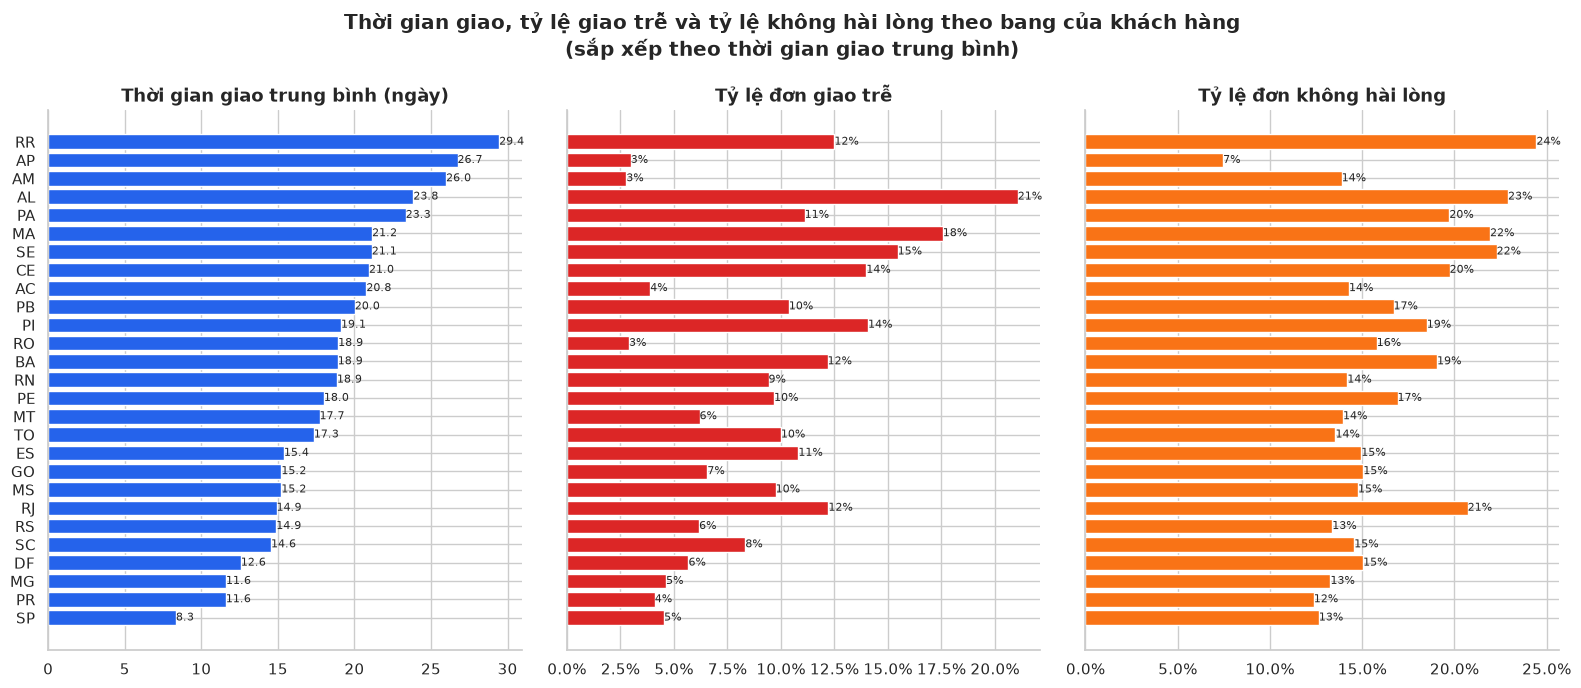

In [13]:
state = q(f'''
    SELECT customer_state, {CX_METRICS},
           avg(CASE WHEN is_delivered = 1 THEN delivery_days END) AS avg_delivery_days,
           avg(is_late) AS late_rate, avg(freight_value) AS avg_freight
    FROM order_cx GROUP BY 1 ORDER BY orders DESC''')

s = state.sort_values("avg_delivery_days")
fig, axes = plt.subplots(1, 3, figsize=(16, 7), sharey=True)
b = axes[0].barh(s.customer_state, s.avg_delivery_days, color=C_MAIN)
axes[0].bar_label(b, fmt="%.1f", fontsize=8); axes[0].set_title("Thời gian giao trung bình (ngày)")
b = axes[1].barh(s.customer_state, s.late_rate, color=C_BAD)
axes[1].bar_label(b, labels=[f"{v:.0%}" for v in s.late_rate], fontsize=8); pct_axis(axes[1], "x"); axes[1].set_title("Tỷ lệ đơn giao trễ")
b = axes[2].barh(s.customer_state, s.negative_rate, color=C_ORANGE)
axes[2].bar_label(b, labels=[f"{v:.0%}" for v in s.negative_rate], fontsize=8); pct_axis(axes[2], "x")
axes[2].set_title("Tỷ lệ đơn không hài lòng")
plt.suptitle("Thời gian giao, tỷ lệ giao trễ và tỷ lệ không hài lòng theo bang của khách hàng\n(sắp xếp theo thời gian giao trung bình)", fontweight="bold")
plt.tight_layout(); plt.show()

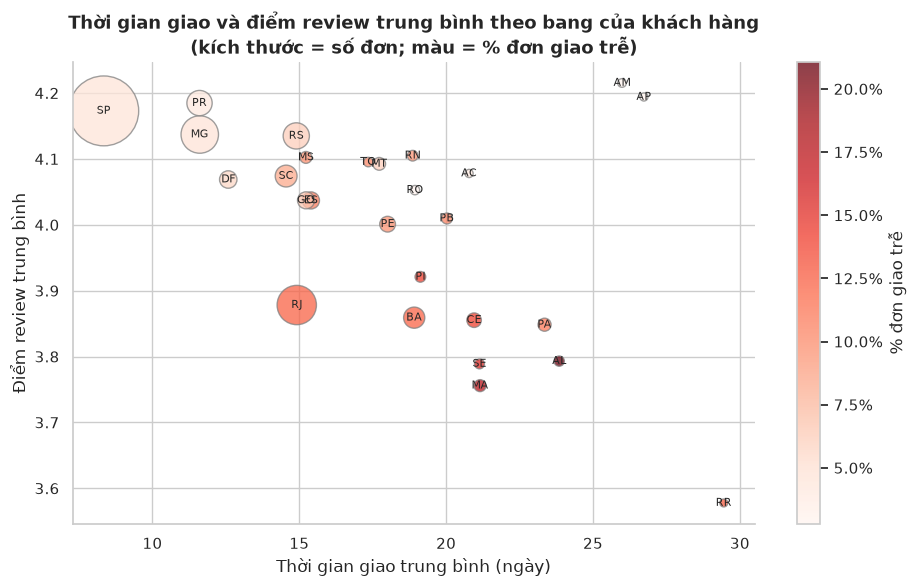

Tương quan (theo bang) giữa thời gian giao TB và điểm TB: -0.498
customer_state  orders  avg_score  negative_rate  avg_delivery_days  late_rate  avg_freight
            SP   41157      4.173          0.127              8.343      0.045       17.365
            RJ   12718      3.878          0.207             14.913      0.122       23.927
            MG   11471      4.137          0.133             11.611      0.046       23.479
            RS    5381      4.135          0.134             14.897      0.062       24.893
            PR    4964      4.185          0.124             11.603      0.041       23.562
            SC    3581      4.074          0.146             14.552      0.083       24.836
            BA    3334      3.859          0.191             18.912      0.122       29.821
            DF    2101      4.069          0.151             12.581      0.057       23.748
            ES    2007      4.037          0.150             15.396      0.108       24.519
            GO 

In [14]:
fig, ax = plt.subplots(figsize=(11, 6))
sc = ax.scatter(state.avg_delivery_days, state.avg_score, s=state.orders / state.orders.max() * 2500 + 30,
                c=state.late_rate, cmap="Reds", alpha=0.75, edgecolor="grey")
for _, row in state.iterrows():
    ax.annotate(row.customer_state, (row.avg_delivery_days, row.avg_score), ha="center", va="center", fontsize=8)
plt.colorbar(sc, label="% đơn giao trễ", format=mtick.PercentFormatter(1.0))
ax.set_xlabel("Thời gian giao trung bình (ngày)"); ax.set_ylabel("Điểm review trung bình")
ax.set_title("Thời gian giao và điểm review trung bình theo bang của khách hàng\n(kích thước = số đơn; màu = % đơn giao trễ)"); plt.show()
print("Tương quan (theo bang) giữa thời gian giao TB và điểm TB:",
      round(state[["avg_delivery_days", "avg_score"]].corr().iloc[0, 1], 3))
print(state.round(3).to_string(index=False))

> **🔎 Kết quả chính**
> - SP giao nhanh nhất (8,7 ngày, 4,5% trễ, 12,6% không hài lòng). Các bang Bắc/Đông Bắc (RR, AP, AM, AL, PA, MA) phải chờ 21–29 ngày.
> - Bang đáng lo nhất về trải nghiệm: **AL** (21% trễ, 23,5% không hài lòng), **MA** (17,5% / 22%), **SE**, **RR**. **RJ** đáng chú ý vì quy mô lớn (12.844 đơn) nhưng 12% trễ và 20,6% không hài lòng.
> - Tương quan theo bang giữa thời gian giao và điểm TB là −0,5.

## 6. Ngành hàng — nhóm sản phẩm nào gây bất mãn?
*Câu hỏi: "Ngành hàng lớn nào có tỷ lệ khách không hài lòng cao? Do sản phẩm hay do giao hàng?"*

Một đơn có thể có nhiều ngành hàng, nên điểm của đơn được gán cho từng cặp *(đơn, ngành hàng)* không trùng lặp. Ngành của dòng sản phẩm theo quy tắc chung `CATEGORY_SQL` (tên tiếng Anh → tên gốc → `unknown`), giống `product` và `seller`.

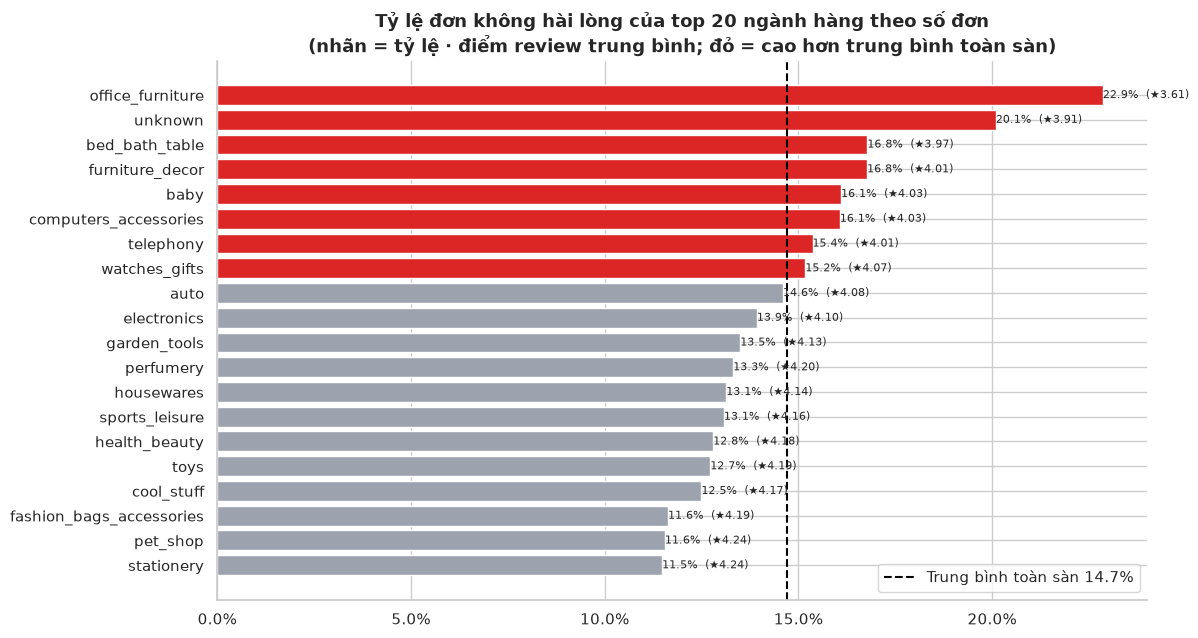

In [15]:
cat = q(f'''
    WITH order_cat AS (
        SELECT DISTINCT i.order_key, {CATEGORY_SQL} AS category
        FROM fact_order_items i
        JOIN dim_product p ON p.product_key = i.product_key
        LEFT JOIN dim_category cat ON cat.category_key = p.category_key)
    SELECT category, {CX_METRICS},
           avg(is_late) AS late_rate,
           avg(CASE WHEN is_delivered = 1 THEN delivery_days END) AS avg_delivery_days
    FROM order_cat JOIN order_cx USING (order_key)
    GROUP BY 1 ORDER BY orders DESC''')
top_cat = cat.head(20).sort_values("negative_rate")

fig, ax = plt.subplots(figsize=(12, 7))
avg_neg = kpi["negative_rate"]
b = ax.barh(top_cat.category, top_cat.negative_rate,
            color=[C_BAD if v > avg_neg else C_GREY for v in top_cat.negative_rate])
ax.bar_label(b, labels=[f"{v:.1%}  (★{s:.2f})" for v, s in zip(top_cat.negative_rate, top_cat.avg_score)], fontsize=8)
ax.axvline(avg_neg, color="black", ls="--", label=f"Trung bình toàn sàn {avg_neg:.1%}")
pct_axis(ax, "x"); ax.legend(loc="lower right")
ax.set_title("Tỷ lệ đơn không hài lòng của top 20 ngành hàng theo số đơn\n(nhãn = tỷ lệ · điểm review trung bình; đỏ = cao hơn trung bình toàn sàn)"); plt.show()

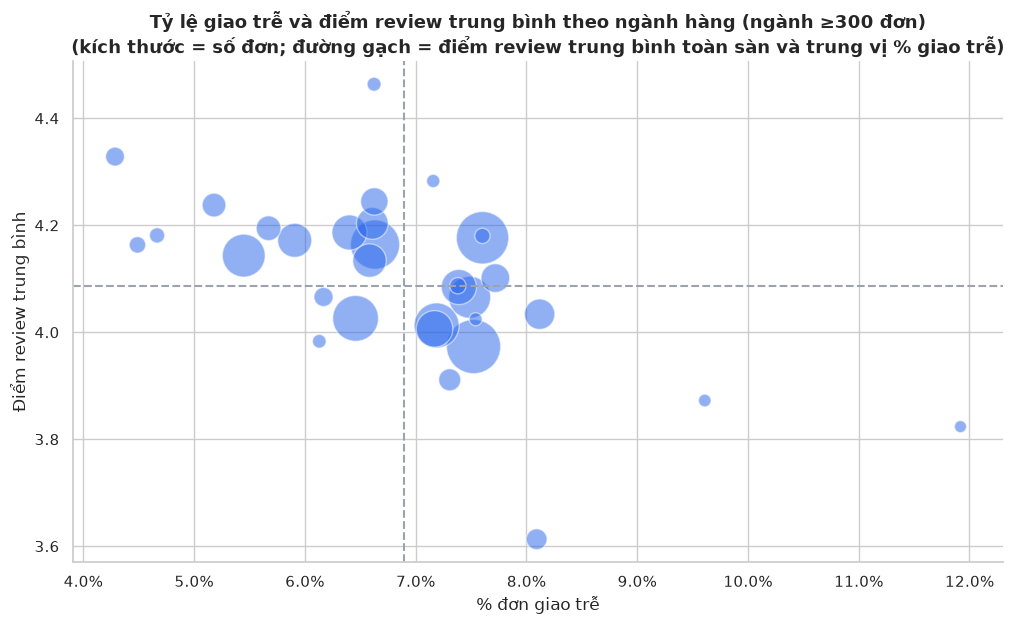

                       category  orders  avg_score  negative_rate  late_rate  avg_delivery_days
                 bed_bath_table    9275      3.973          0.168      0.075             12.596
                  health_beauty    8684      4.177          0.128      0.076             11.676
                 sports_leisure    7636      4.164          0.131      0.066             11.823
          computers_accessories    6600      4.026          0.161      0.065             12.789
                furniture_decor    6373      4.013          0.168      0.072             12.652
                     housewares    5774      4.143          0.131      0.054             10.690
                  watches_gifts    5525      4.065          0.152      0.075             12.404
                      telephony    4150      4.006          0.154      0.072             12.516
                           auto    3836      4.085          0.146      0.074             11.951
                           toys    3830 

In [16]:
big_cat = cat[cat.orders >= 300]
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.scatter(big_cat.late_rate, big_cat.avg_score, s=big_cat.orders / big_cat.orders.max() * 1500 + 20,
           color=C_MAIN, alpha=0.5, edgecolor="white")
ax.axhline(kpi["avg_review_score"], color=C_GREY, ls="--"); ax.axvline(big_cat.late_rate.median(), color=C_GREY, ls="--")
pct_axis(ax, "x"); ax.set_xlabel("% đơn giao trễ"); ax.set_ylabel("Điểm review trung bình")
ax.set_title("Tỷ lệ giao trễ và điểm review trung bình theo ngành hàng (ngành ≥300 đơn)\n"
             "(kích thước = số đơn; đường gạch = điểm review trung bình toàn sàn và trung vị % giao trễ)")
plt.show()
print(cat.head(25).round(3).to_string(index=False))

> **🔎 Kết quả chính**
> - **office_furniture** kém nhất trong các ngành lớn (★3,62, 22,7% không hài lòng, giao TB 20,6 ngày), tiếp theo là nhóm nội thất/gia dụng cồng kềnh: **bed_bath_table** (16,7%), **furniture_decor** (16,6%), **computers_accessories** (16,0%).
> - Những ngành được đánh giá kém thường là các ngành chứa đồ dùng cồng kềnh -> Thời gian giao lâu -> Đánh giá kém
> - Ngành tốt: luggage_accessories (9,2%), stationery (11,4%), fashion_bags_accessories, pet_shop. Đơn có sản phẩm không rõ ngành (`unknown`) cũng kém (20,3%).

## 7. Người bán — ai đang kéo trải nghiệm xuống?
*Câu hỏi: "Chất lượng người bán phân hóa thế nào? Có phải một nhóm nhỏ người bán gây ra phần lớn đơn không hài lòng?"*

Số người bán: 3,084 | có ≥30 đơn: 627


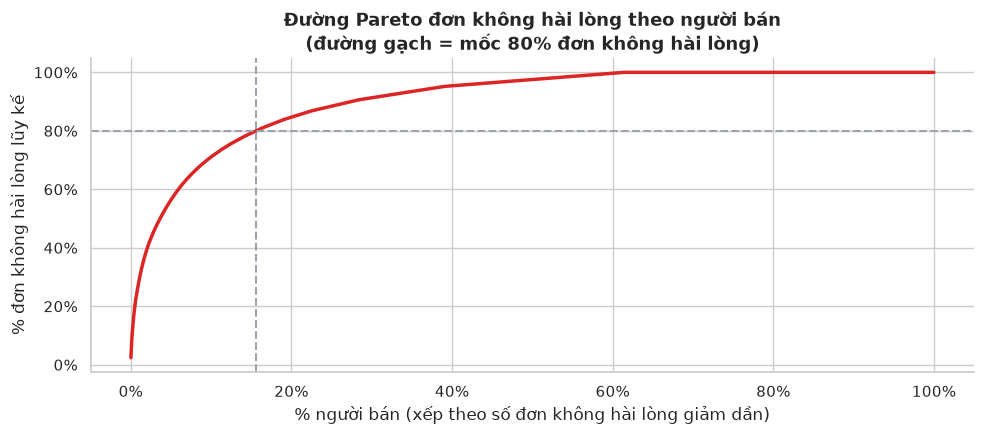

In [17]:
seller_perf = q(f'''
    WITH order_seller AS (SELECT DISTINCT order_key, seller_key FROM fact_order_items)
    SELECT s.seller_id, s.state AS seller_state, {CX_METRICS},
           coalesce(sum(is_negative), 0) AS negative_orders, avg(is_late) AS late_rate
    FROM order_seller JOIN order_cx USING (order_key)
    LEFT JOIN dim_seller s USING (seller_key)
    GROUP BY 1, 2''')
active = seller_perf[seller_perf.orders >= MIN_SELLER_ORDERS]
print(f"Số người bán: {len(seller_perf):,} | có ≥{MIN_SELLER_ORDERS} đơn: {len(active):,}")

pareto = seller_perf.sort_values("negative_orders", ascending=False)
pareto["cum_share"] = pareto.negative_orders.cumsum() / pareto.negative_orders.sum()
pareto["seller_share"] = np.arange(1, len(pareto) + 1) / len(pareto)
seller_share_at_80 = pareto.loc[pareto.cum_share >= 0.8, "seller_share"].iloc[0]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(pareto.seller_share, pareto.cum_share, color=C_BAD, lw=2.5)
ax.axhline(0.8, color=C_GREY, ls="--"); ax.axvline(seller_share_at_80, color=C_GREY, ls="--")
pct_axis(ax); pct_axis(ax, "x"); ax.set_xlabel("% người bán (xếp theo số đơn không hài lòng giảm dần)"); ax.set_ylabel("% đơn không hài lòng lũy kế")
ax.set_title(f"Đường Pareto đơn không hài lòng theo người bán\n(đường gạch = mốc 80% đơn không hài lòng)"); plt.tight_layout(); plt.show()

> **Lưu ý:** Watchlist bên dưới chỉ xét người bán có ≥ 30 đơn. Phân bố điểm review của người bán (theo GMV) xem `seller` §5.

In [18]:
watchlist = active.sort_values("negative_orders", ascending=False).head(15)
print(watchlist[["seller_id", "seller_state", "orders", "avg_score", "negative_orders", "negative_rate", "late_rate"]]
      .round(3).to_string(index=False))

                       seller_id seller_state  orders  avg_score  negative_orders  negative_rate  late_rate
4a3ca9315b744ce9f8e9374361493884           SP    1790      3.824              343          0.195      0.098
6560211a19b47992c3666cc44a7e94c0           SP    1803      3.935              308          0.173      0.053
7c67e1448b00f6e969d365cea6b010ab           SP     981      3.482              252          0.261      0.092
cc419e0650a3c5ba77189a1882b7556a           SP    1701      4.079              249          0.150      0.053
1f50f920176fa81dab994f9023523100           SP    1396      4.130              197          0.142      0.089
ea8482cd71df3c1969d7b9473ff13abc           SP    1121      3.997              171          0.154      0.087
1025f0e2d44d7041d6cf58b6550e0bfa           SP     903      4.002              152          0.172      0.079
4869f7a5dfa277a7dca6462dcf3b52b2           SP    1120      4.127              151          0.136      0.106
da8622b14eb17ae2831f4ac5b9da

In [19]:
# Người bán và khách cùng bang vs khác bang (chỉ đơn mà mọi người bán cùng 1 bang)
route = q(f'''
    WITH seller_state_order AS (
        SELECT i.order_key, arbitrary(s.state) AS seller_state, count(DISTINCT s.state) AS n_seller_states
        FROM (SELECT DISTINCT order_key, seller_key FROM fact_order_items) i
        JOIN dim_seller s USING (seller_key) GROUP BY 1)
    SELECT CASE WHEN seller_state = customer_state THEN 'Cùng bang' ELSE 'Khác bang' END AS route,
           {CX_METRICS}, avg(delivery_days) AS avg_delivery_days, avg(is_late) AS late_rate
    FROM delivered JOIN seller_state_order USING (order_key)
    WHERE n_seller_states = 1
    GROUP BY 1''')
print(route.round(3).to_string(index=False))

    route  orders  avg_score  negative_rate  avg_delivery_days  late_rate
Cùng bang   34069      4.268          0.103              7.531      0.046
Khác bang   60536      4.105          0.139             14.784      0.082


> **🔎 Kết quả chính**
> - **16% người bán chiếm 80% số đơn không hài lòng** (Pareto). Watchlist toàn người bán ở SP, trong đó có người bán gần 1.000 đơn với 25,8% không hài lòng.
> - Khi người bán **cùng bang** với khách: giao 7,9 ngày, 4,5% trễ, 10,3% không hài lòng; **khác bang**: 15,1 ngày, 8,1% trễ, 13,8% không hài lòng.

## 8. Đặc điểm đơn hàng & thanh toán
*Câu hỏi: "Đơn nhiều sản phẩm, nhiều người bán, phí ship cao, trả góp... có làm khách kém hài lòng hơn?"*

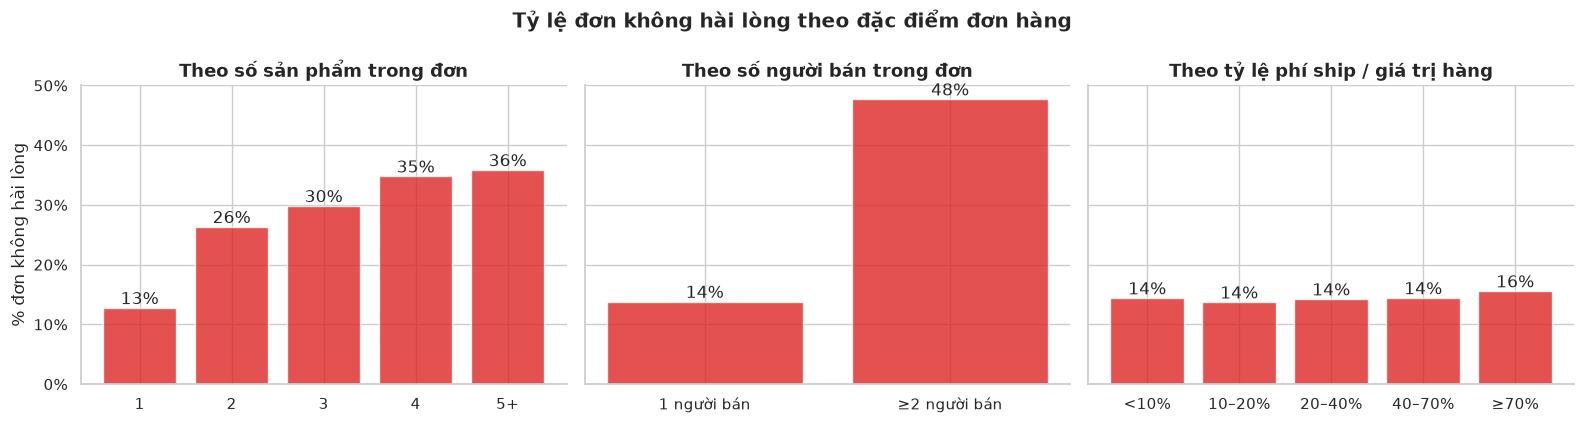

grp  orders  avg_score  negative_rate
  1   86518      4.159          0.127
  2    7270      3.657          0.263
  3    1278      3.514          0.298
  4     489      3.347          0.348
 5+     441      3.294          0.358 

         grp  orders  avg_score  negative_rate
 1 người bán   94794      4.120          0.138
≥2 người bán    1202      2.849          0.477 

   grp  orders  avg_score  negative_rate
  <10%   15330      4.136          0.144
10–20%   27547      4.125          0.137
20–40%   31135      4.099          0.142
40–70%   14501      4.081          0.144
  ≥70%    7483      4.033          0.155 



In [20]:
def driver_table(group_expr, order):
    return ordered(q(f"SELECT {group_expr} AS grp, {CX_METRICS} FROM reviewed WHERE n_items IS NOT NULL GROUP BY 1"),
                   "grp", order)

FREIGHT_BINS = [(0.1, "<10%"), (0.2, "10–20%"), (0.4, "20–40%"), (0.7, "40–70%")]
items_tbl = driver_table(band_sql("n_items", [(1, "1"), (2, "2"), (3, "3"), (4, "4")], "5+", upper_inclusive=True),
                         ["1", "2", "3", "4", "5+"])
sellers_tbl = driver_table(band_sql("n_sellers", [(1, "1 người bán")], "≥2 người bán", upper_inclusive=True),
                           ["1 người bán", "≥2 người bán"])
freight_tbl = driver_table(band_sql("freight_ratio", FREIGHT_BINS, "≥70%", upper_inclusive=True, null_label="n/a"),
                           [label for _, label in FREIGHT_BINS] + ["≥70%"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, tbl, title in [(axes[0], items_tbl, "Theo số sản phẩm trong đơn"),
                       (axes[1], sellers_tbl, "Theo số người bán trong đơn"),
                       (axes[2], freight_tbl, "Theo tỷ lệ phí ship / giá trị hàng")]:
    b = ax.bar(tbl.grp, tbl.negative_rate, color=C_BAD, alpha=0.8)
    ax.bar_label(b, labels=[f"{v:.0%}" for v in tbl.negative_rate]); pct_axis(ax); ax.set_title(title)
axes[0].set_ylabel("% đơn không hài lòng")
plt.suptitle("Tỷ lệ đơn không hài lòng theo đặc điểm đơn hàng", fontweight="bold"); plt.tight_layout(); plt.show()
for t in (items_tbl, sellers_tbl, freight_tbl):
    print(t.round(3).to_string(index=False), "\n")

In [21]:
pay_tbl = q(f'''SELECT payment_type, {CX_METRICS}, avg(payment_value) AS avg_order_value
                FROM reviewed WHERE payment_type IS NOT NULL AND n_items IS NOT NULL GROUP BY 1 ORDER BY orders DESC''')
INST_BINS = [(1, "1 kỳ"), (3, "2–3 kỳ"), (6, "4–6 kỳ"), (10, "7–10 kỳ")]
inst_tbl = ordered(q(f'''
    SELECT {band_sql("installments", INST_BINS, ">10 kỳ", upper_inclusive=True)} AS grp, {CX_METRICS}, avg(payment_value) AS avg_order_value
    FROM reviewed WHERE payment_type = 'credit_card' AND n_items IS NOT NULL GROUP BY 1'''), "grp", [label for _, label in INST_BINS] + [">10 kỳ"])
print(pay_tbl.round(3).to_string(index=False), "\n")
print(inst_tbl.round(3).to_string(index=False))

payment_type  orders  avg_score  negative_rate  avg_order_value
 credit_card   72493      4.104          0.143          167.056
      boleto   19070      4.106          0.139          144.865
     voucher    2969      4.075          0.150          114.527
  debit_card    1463      4.190          0.126          141.723

 

    grp  orders  avg_score  negative_rate  avg_order_value
   1 kỳ   23296      4.172          0.126          100.702
 2–3 kỳ   21886      4.096          0.143          135.937
 4–6 kỳ   15602      4.076          0.149          182.842
7–10 kỳ   11384      4.023          0.169          335.895
 >10 kỳ     325      3.902          0.203          346.959


> **🔎 Kết quả chính**
> - Đơn càng nhiều sản phẩm / người bán càng dễ bất mãn: 1 sản phẩm 12,7% không hài lòng, 2 sản phẩm 26,4%, ≥5 sản phẩm 35,7%; đơn **≥2 người bán: 47,6%** (giao tách kiện).
> - Tỷ lệ phí ship / giá trị hàng (13,6–15,5%) và hình thức thanh toán (12,7–14,8%) gần như **không** tạo khác biệt.
> - Trả góp nhiều kỳ có % không hài lòng cao hơn (1 kỳ 12,5% → >10 kỳ 20,4%), nhiều khả năng do đi kèm sản phẩm đắt/cồng kềnh, không phải do bản thân việc trả góp.

## 9. Trải nghiệm đơn đầu có liên quan đến việc quay lại?
*Câu hỏi: "Khách có đơn đầu tiên tốt có quay lại nhiều hơn không?"* (Phân bố số đơn / khách và cohort giữ chân xem `customer_behaviour` §7.)

Dùng tỷ lệ **mua lại trong 90 ngày** sau đơn đầu, chỉ với khách có đơn đầu trước `ngày cuối dữ liệu − 90 ngày`, để các nhóm khách
được theo dõi cùng một khoảng thời gian.

Mốc cuối dữ liệu: 2018-10-17 17:30:18


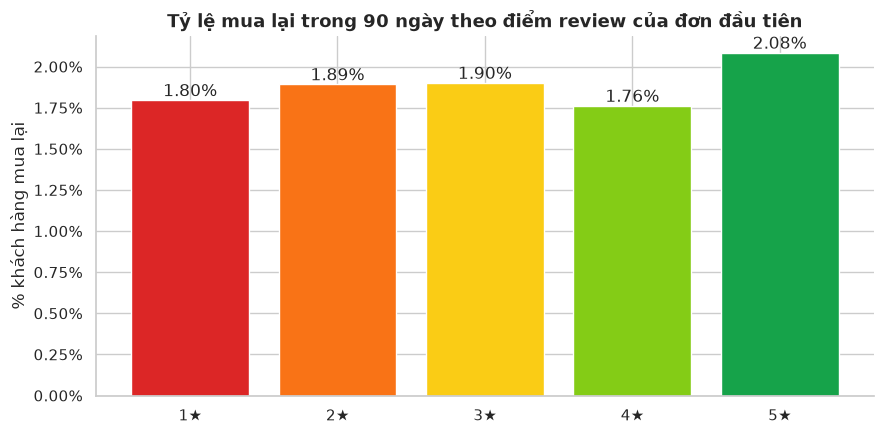

 score_int  customers  repurchase_rate
         1      10075           0.0180
         2       2747           0.0189
         3       7151           0.0190
         4      16514           0.0176
         5      48394           0.0208 

  first_delivery  customers  repurchase_rate
Đơn đầu đúng hạn      77328           0.0223
 Đơn đầu trễ hạn       5837           0.0197


In [22]:
REPURCHASE_WINDOW_DAYS = 90
# Mốc cuối dữ liệu: chỉ xét khách có đơn đầu cách mốc này ≥ REPURCHASE_WINDOW_DAYS ngày (đủ thời gian quan sát mua lại)
DATA_END = q("SELECT max(order_purchase_timestamp) AS t FROM order_cx").t.iloc[0]
print(f"Mốc cuối dữ liệu: {DATA_END:%Y-%m-%d %H:%M:%S}")
con.execute(f'''
CREATE OR REPLACE TABLE first_orders AS
WITH ranked AS (
    SELECT *, row_number() OVER w AS rn, lead(order_purchase_timestamp) OVER w AS next_purchase
    FROM order_cx
    WINDOW w AS (PARTITION BY customer_key ORDER BY order_purchase_timestamp, order_key))
SELECT *,
       CAST((next_purchase IS NOT NULL
        AND next_purchase <= order_purchase_timestamp + INTERVAL '{REPURCHASE_WINDOW_DAYS}' DAY) AS INTEGER) AS repurchase_90d
FROM ranked
WHERE rn = 1
  AND order_purchase_timestamp <= TIMESTAMP '{DATA_END}' - INTERVAL '{REPURCHASE_WINDOW_DAYS}' DAY
''')

by_first_score = q('''SELECT score_int, count(*) AS customers, avg(repurchase_90d) AS repurchase_rate
                      FROM first_orders WHERE score_int IS NOT NULL GROUP BY 1 ORDER BY 1''')
by_first_late = q('''SELECT CASE WHEN is_late = 1 THEN 'Đơn đầu trễ hạn' ELSE 'Đơn đầu đúng hạn' END AS first_delivery,
                            count(*) AS customers, avg(repurchase_90d) AS repurchase_rate
                     FROM first_orders WHERE is_late IS NOT NULL GROUP BY 1''')

fig, ax = plt.subplots(figsize=(9, 4.5))
b = ax.bar(by_first_score.score_int.astype(str) + "★", by_first_score.repurchase_rate,
           color=[SCORE_COLORS[s] for s in by_first_score.score_int])
ax.bar_label(b, labels=[f"{v:.2%}" for v in by_first_score.repurchase_rate]); pct_axis(ax)
ax.set_title(f"Tỷ lệ mua lại trong {REPURCHASE_WINDOW_DAYS} ngày theo điểm review của đơn đầu tiên")
ax.set_ylabel("% khách hàng mua lại")
plt.tight_layout(); plt.show()
print(by_first_score.round(4).to_string(index=False), "\n")
print(by_first_late.round(4).to_string(index=False))

> **🔎 Kết quả chính**
> - Tỷ lệ mua lại trong 90 ngày chỉ ~2% và **gần như không đổi theo điểm đơn đầu** (1★: 1,84% · 5★: 2,13%) hay theo giao đúng/trễ hạn (2,24% vs 1,98%).
> - Trải nghiệm đơn đầu **không** quyết định việc quay lại; giữ chân khách cần đòn bẩy khác (CRM, khuyến mãi, chương trình thành viên).

## 10. Tổng hợp — yếu tố nào gắn với đơn không hài lòng nhiều nhất?
So sánh % đơn không hài lòng giữa *nhóm có yếu tố* và *nhóm không có*, **trong cùng một tập đơn phù hợp**:
yếu tố giao hàng chỉ so trong các đơn đã giao; các yếu tố khác so trong mọi đơn có review. Đây là so sánh mô tả, không phải bằng chứng nhân quả.

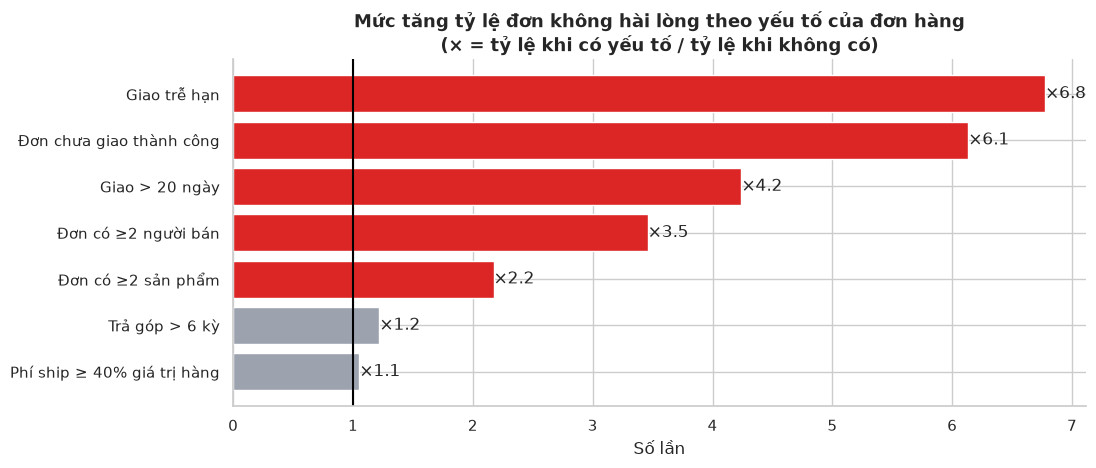

                     Yếu tố  % đơn có yếu tố  % không hài lòng (có)  % không hài lòng (không)  Gấp (lần)
               Giao trễ hạn            0.067                  0.625                     0.092      6.775
   Đơn chưa giao thành công            0.029                  0.786                     0.128      6.134
             Giao > 20 ngày            0.130                  0.383                     0.090      4.241
        Đơn có ≥2 người bán            0.013                  0.477                     0.138      3.459
         Đơn có ≥2 sản phẩm            0.099                  0.277                     0.127      2.172
             Trả góp > 6 kỳ            0.122                  0.175                     0.143      1.220
Phí ship ≥ 40% giá trị hàng            0.229                  0.148                     0.140      1.053


In [23]:
FACTORS = [  # (tên yếu tố, điều kiện SQL, tập đơn để so sánh)
    ("Giao trễ hạn", "is_late = 1", "reviewed_delivered"),
    ("Giao > 20 ngày", "delivery_days > 20", "reviewed_delivered"),
    ("Đơn chưa giao thành công", "is_delivered = 0", "reviewed"),
    ("Đơn có ≥2 người bán", "n_sellers >= 2", "reviewed"),
    ("Đơn có ≥2 sản phẩm", "n_items >= 2", "reviewed"),
    ("Phí ship ≥ 40% giá trị hàng", "freight_ratio >= 0.4", "reviewed"),
    ("Trả góp > 6 kỳ", "installments > 6", "reviewed"),
]
drivers = pd.concat([q(f'''
    SELECT '{name}' AS "Yếu tố",
           avg(CAST(({cond}) AS INTEGER)) AS "% đơn có yếu tố",
           avg(CASE WHEN {cond} THEN is_negative END) AS "% không hài lòng (có)",
           avg(CASE WHEN NOT ({cond}) THEN is_negative END) AS "% không hài lòng (không)"
    FROM {population} WHERE ({cond}) IS NOT NULL''') for name, cond, population in FACTORS])
drivers["Gấp (lần)"] = drivers["% không hài lòng (có)"] / drivers["% không hài lòng (không)"].replace(0, np.nan)
drivers = drivers.dropna(subset=["Gấp (lần)"]).sort_values("Gấp (lần)", ascending=False)

fig, ax = plt.subplots(figsize=(11, 4.5))
b = ax.barh(drivers["Yếu tố"], drivers["Gấp (lần)"], color=[C_BAD if v >= 1.5 else C_GREY for v in drivers["Gấp (lần)"]])
ax.bar_label(b, fmt="×%.1f"); ax.axvline(1, color="black"); ax.invert_yaxis()
ax.set_title("Mức tăng tỷ lệ đơn không hài lòng theo yếu tố của đơn hàng\n(× = tỷ lệ khi có yếu tố / tỷ lệ khi không có)"); ax.set_xlabel("Số lần"); plt.show()
print(drivers.round(3).to_string(index=False))

> **🔎 Kết quả chính**
> - Xếp hạng theo mức tăng % không hài lòng: **giao trễ hạn ×6,8** (62,4% vs 9,2%) > **đơn chưa giao thành công ×6,1** > **giao >20 ngày ×4,1** > **đơn ≥2 người bán ×3,5** > đơn ≥2 sản phẩm ×2,2.
> - Trả góp >6 kỳ (×1,2) và phí ship cao (×1,05) gần như không đáng kể. Ưu tiên cải thiện: **đúng hạn giao hàng** và **gộp kiện cho đơn nhiều người bán/nhiều sản phẩm**.

## 11. Tổng kết
1. **Giao trễ là nguồn bất mãn lớn nhất:** đơn trễ có 62% không hài lòng so với 9% đơn đúng hạn (×6,8); trễ ≥ 8 ngày ~80% (§4, §10).
2. **Có 3 tháng khủng hoảng chất lượng** (11/2017, 02–03/2018), đã phục hồi từ 04/2018 (§3).
3. **Vùng xa và RJ phục vụ kém:** AL, MA, SE, RR có % trễ và % không hài lòng cao nhất; RJ đáng chú ý vì quy mô lớn (§5).
4. **Nhóm nhỏ người bán gây phần lớn bất mãn:** 16% người bán chiếm 80% đơn không hài lòng; đơn có ≥ 2 người bán 47,6% không hài lòng (§7, §8).

In [24]:
con.close()